
# 03 - Closed-set Baselines and Model Selection

**Inputs (full mode):** `data/interim/split_metadata.csv`, `handcrafted_features_full.csv`, `clap_embeddings_full.npz`, `mert_embeddings_full.npz`, `muq_embeddings_full.npz`.

**Research question:** Do handcrafted acoustic features, CLAP, MERT, or MuQ provide more useful information for identifying the five AI music generators? Does increasing the training set size improve generalization?

This notebook does not retrain pretrained audio encoders. It reads the embeddings computed in notebook 02 and trains three downstream classifiers (Logistic Regression, SVM, and k-NN) per representation: 12 combinations in total.

**Outputs:** Full validation comparison table and figure; top-5 validation/test scores; per-example validation/test predictions for all five models (for notebook 04).

In [35]:
from pathlib import Path
import os

PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
PROJECT_ROOT


WindowsPath('d:/UCU/33333333333333333/AI/AI-vs-Original-Music-Classification')

## 1. Configuration and full-dataset checks
All representations must describe the same audio clips with identical (track_id, generator, split) keys. Files generated by notebook 02 are trusted local artifacts.

In [39]:
import json
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.metrics import accuracy_score, balanced_accuracy_score, precision_recall_fscore_support, f1_score
from ai_music_origin.config import load_config
from ai_music_origin.models import build_logistic_regression, build_svm, build_knn, build_baseline

In [ ]:
DATASET_MODE = "full"  # "full" is intended; "pilot" is available for a quick check
TOP_K = 5

In [ ]:
suffix = "_full" if DATASET_MODE == "full" else ""
metadata_path = PROJECT_ROOT / "data" / "interim" /  "split_metadata.csv" if DATASET_MODE == "full" else "pilot_metadata.csv"
results_dir = PROJECT_ROOT / "results"
figures_dir = results_dir / "figures"
results_dir.mkdir(parents=True, exist_ok=True)
figures_dir.mkdir(parents=True, exist_ok=True)

config = load_config(PROJECT_ROOT / "config/default.yaml")
metadata = pd.read_csv(metadata_path, dtype={"track_id": str})
keys = ["track_id", "generator", "split"]
print("Dataset:", DATASET_MODE, "| Clips:", len(metadata), "| Generators:", metadata["generator"].nunique())
display(pd.crosstab(metadata["split"], metadata["generator"]))

Dataset: full | Clips: 27605 | Generators: 5


generator,MusicGen_medium,audioldm2,musicldm,mustango,stable_audio_open
split,,,,,
test,829,829,829,829,829
train,3864,3864,3864,3864,3864
validation,828,828,828,828,828


### Dataset used in this experiment
The full FakeMusicCaps split contains 27,605 clips from five generators, with identical class counts: 3,864 clips per generator for training, 828 for validation, and 829 for testing. The model is not fitted on all 27,605 examples: it is trained on 19,320, selected on 4,140 validation examples, and tested on 4,145 held-out examples.

## 2. Load and align all four representations
The NPZ loaders read the `embeddings`, `track_ids`, `generators`, and `splits` arrays saved in notebook 02.

In [43]:
def align_vectors(df, vectors, stored_ids, stored_generators, stored_splits, source):
    stored_keys = pd.MultiIndex.from_arrays([
        np.asarray(stored_ids, dtype=str),
        np.asarray(stored_generators, dtype=str),
        np.asarray(stored_splits, dtype=str)])
    target_keys = pd.MultiIndex.from_frame(df[["track_id", "generator", "split"]].astype(str))
    if not stored_keys.is_unique:
        raise ValueError(f"Duplicate keys in {source}")
    if len(stored_keys) != len(target_keys):
        raise ValueError(f"Unexpected number of examples in {source}")
    positions = stored_keys.get_indexer(target_keys)
    if (positions < 0).any() or not np.array_equal(np.sort(positions), np.arange(len(target_keys))):
        raise ValueError(f"Missing or mismatched IDs/splits in {source}")
    aligned = np.asarray(vectors[positions], dtype=np.float32)
    if aligned.ndim != 2 or not np.isfinite(aligned).all():
        raise ValueError(f"Invalid embedding matrix in {source}")
    return aligned


def load_npz_representation(name, path, df):
    if not path.is_file():
        raise FileNotFoundError(f"Missing {name}: {path}. Extract it in notebook 02 first.")
    with np.load(path, allow_pickle=True) as saved:
        needed = {"embeddings", "track_ids", "generators", "splits"}
        if not needed.issubset(saved.files):
            raise ValueError(f"{name} missing arrays: {needed - set(saved.files)}")
        result = align_vectors(df, saved["embeddings"], saved["track_ids"], saved["generators"], saved["splits"], path.name)
    return result

hc_path = PROJECT_ROOT / "data/interim" / f"handcrafted_features{suffix}.csv"
hc = pd.read_csv(hc_path, dtype={"track_id": str})
feature_cols = [c for c in hc if c not in keys]
assert len(feature_cols) == 36, f"Expected 36 handcrafted features; got {len(feature_cols)}"
assert all(pd.api.types.is_numeric_dtype(hc[c]) for c in feature_cols)

hc_vectors = align_vectors(metadata, hc[feature_cols].to_numpy(dtype=np.float32), hc["track_id"], hc["generator"], hc["split"], hc_path.name)
representations = {"Handcrafted": hc_vectors}
for name, filename in [("CLAP", f"clap_embeddings{suffix}.npz"), ("MERT", f"mert_embeddings{suffix}.npz"), ("MuQ", f"muq_embeddings{suffix}.npz")]:
    representations[name] = load_npz_representation(name, PROJECT_ROOT / "data/interim" / filename, metadata)
representation_summary = pd.DataFrame([
    {"Representation": name, "Samples": x.shape[0], "Dimensions": x.shape[1]}
    for name, x in representations.items()])
display(representation_summary)
assert all(x.shape[0] == len(metadata) for x in representations.values())

,Representation,Samples,Dimensions
0,Handcrafted,27605,36
1,CLAP,27605,512
2,MERT,27605,768
3,MuQ,27605,1024


The four feature matrices contain the same 27,605 labelled audio clips. Their dimensions differ (36 / 512 / 768 / 1,024)

## 3. Twelve experiments: representation × classifier
**Research question:** How much does generator attribution depend on the audio representation, and does a more flexible classifier improve performance?
We evaluate 12 combinations: four representations (36 handcrafted features, 512-dimensional CLAP, 768-dimensional MERT, and 1,024-dimensional MuQ) × three classifiers.
- Logistic Regression is a fast, interpretable linear reference; 
- SVM can learn more flexible decision boundaries depending on its kernel; 
- k-NN tests whether generators form useful local neighborhoods.
Our model builders in `src/ai_music_origin/models.py` include feature scaling in their pipelines, preventing validation/test leakage.

In [57]:
SPLIT = metadata["split"].to_numpy()
LABELS = metadata["generator"].astype(str).to_numpy()
TRAIN, VAL, TEST = (SPLIT == s for s in ["train", "validation", "test"])
class_names = sorted(metadata["generator"].unique().tolist())

In [ ]:
model_factories = {"Logistic Regression": build_logistic_regression}
model_factories.update({"SVM": build_svm, "k-NN": build_knn})


def measure(y_true, y_pred):
    precision, recall, f1, _ = precision_recall_fscore_support(y_true, y_pred, labels=class_names, average="macro", zero_division=0)
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Balanced Accuracy": balanced_accuracy_score(y_true, y_pred),
        "Macro F1": f1,
        "Macro Precision": precision,
        "Macro Recall": recall,
    }


def slug(s):
    return str(s).lower().replace(" ", "_").replace("-", "")


def candidate_order(candidate):
    return (-candidate["validation_f1"], candidate["Representation"], candidate["Model"])

rows = []
top_candidates = []
for representation_name, X in representations.items():
    for classifier_name, build_model in model_factories.items():
        model_id = f"{slug(representation_name)}__{slug(classifier_name)}"
        estimator = build_model(config)
        start = time.perf_counter()
        estimator.fit(X[TRAIN], LABELS[TRAIN])
        validation_pred = estimator.predict(X[VAL]).astype(str)
        elapsed = time.perf_counter() - start
        stats = measure(LABELS[VAL], validation_pred)
        rows.append({
            "model_id": model_id,
            "Representation": representation_name,
            "Model": classifier_name,
            "n_features": X.shape[1],
            "n_train": int(TRAIN.sum()),
            "n_validation": int(VAL.sum()),
            **stats,
            "fit_predict_seconds": elapsed,
        })
        print(f"{representation_name:12s} | {classifier_name:20s} | "
              f"Validation Macro F1: {stats['Macro F1']:.4f} | {elapsed:.1f}s")
        top_candidates.append({
            "model_id": model_id,
            "Representation": representation_name,
            "Model": classifier_name,
            "validation_f1": stats["Macro F1"],
            "estimator": estimator,
            "val_predictions": validation_pred,
        })
        top_candidates.sort(key=candidate_order)
        del top_candidates[TOP_K:]  # keep only 5 fitted estimators to limit memory

comparison_df = pd.DataFrame(rows).sort_values(
    ["Macro F1", "Representation", "Model"],
    ascending=[False, True, True], ignore_index=True,
)
comparison_df.insert(0, "validation_rank", np.arange(1, len(comparison_df) + 1))
assert len(comparison_df) == len(representations) * len(model_factories)
print("All validation results (sorted by Macro F1):")
display(comparison_df.round(4))

Handcrafted  | Logistic Regression  | Validation Macro F1: 0.7581 | 0.5s
Handcrafted  | SVM                  | Validation Macro F1: 0.8588 | 8.6s
Handcrafted  | k-NN                 | Validation Macro F1: 0.7594 | 0.2s
CLAP         | Logistic Regression  | Validation Macro F1: 0.9108 | 8.1s
CLAP         | SVM                  | Validation Macro F1: 0.9234 | 54.2s
CLAP         | k-NN                 | Validation Macro F1: 0.8368 | 1.2s
MERT         | Logistic Regression  | Validation Macro F1: 0.9628 | 5.4s
MERT         | SVM                  | Validation Macro F1: 0.9675 | 88.2s
MERT         | k-NN                 | Validation Macro F1: 0.7848 | 1.4s
MuQ          | Logistic Regression  | Validation Macro F1: 0.9800 | 2.2s
MuQ          | SVM                  | Validation Macro F1: 0.9862 | 69.6s
MuQ          | k-NN                 | Validation Macro F1: 0.9052 | 1.9s
All validation results (sorted by Macro F1):


,validation_rank,model_id,Representation,Model,n_features,n_train,n_validation,Accuracy,Balanced Accuracy,Macro F1,Macro Precision,Macro Recall,fit_predict_seconds
0,1,muq__svm,MuQ,SVM,1024,19320,4140,0.9862,0.9862,0.9862,0.9863,0.9862,69.6434
1,2,muq__logistic_regression,MuQ,Logistic Regression,1024,19320,4140,0.9800,0.9800,0.9800,0.9800,0.9800,2.1705
2,3,mert__svm,MERT,SVM,768,19320,4140,0.9674,0.9674,0.9675,0.9683,0.9674,88.1569
3,4,mert__logistic_regression,MERT,Logistic Regression,768,19320,4140,0.9628,0.9628,0.9628,0.9629,0.9628,5.4262
4,5,clap__svm,CLAP,SVM,512,19320,4140,0.9234,0.9234,0.9234,0.9237,0.9234,54.2136
5,6,clap__logistic_regression,CLAP,Logistic Regression,512,19320,4140,0.9109,0.9109,0.9108,0.9109,0.9109,8.0680
6,7,muq__knn,MuQ,k-NN,1024,19320,4140,0.9053,0.9053,0.9052,0.9102,0.9053,1.9044
7,8,handcrafted__svm,Handcrafted,SVM,36,19320,4140,0.8585,0.8585,0.8588,0.8594,0.8585,8.5820
8,9,clap__knn,CLAP,k-NN,512,19320,4140,0.8367,0.8367,0.8368,0.8424,0.8367,1.1625
9,10,mert__knn,MERT,k-NN,768,19320,4140,0.7908,0.7908,0.7848,0.8045,0.7908,1.4265


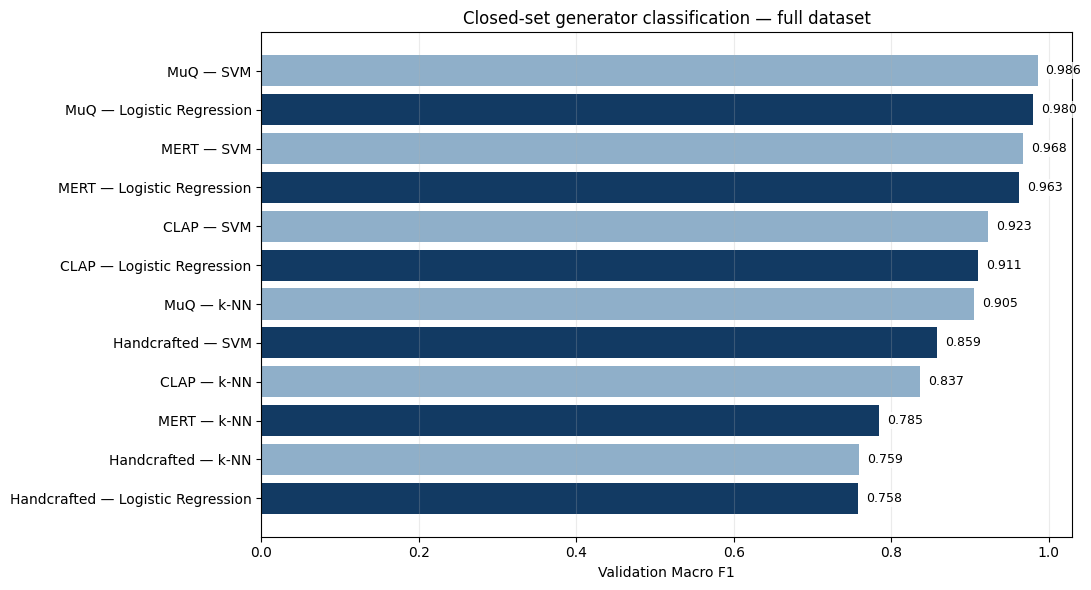

In [ ]:
plot_df = comparison_df.iloc[::-1].copy()
fig, ax = plt.subplots(figsize=(11, max(5, len(plot_df) * 0.5)))
labels_plot = plot_df["Representation"] + " — " + plot_df["Model"]
colors = ["#123A63" if i % 2 == 0 else "#8FAFC9" for i in range(len(plot_df))]
bars = ax.barh(labels_plot, plot_df["Macro F1"], color=colors)
ax.set_xlim(0, 1.03)
ax.set_xlabel("Validation Macro F1")
ax.set_title(f"Closed-set generator classification — {DATASET_MODE} dataset")
ax.grid(axis="x", alpha=0.25)

for bar, v in zip(bars, plot_df["Macro F1"]):
    ax.text(min(v + 0.01, 1.005), bar.get_y() + bar.get_height() / 2, f"{v:.3f}", va="center", ha="left", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", alpha=0.8, pad=1.5))

fig.tight_layout()
fig.savefig(figures_dir / f"baseline_comparison_{DATASET_MODE}.png", dpi=180, bbox_inches="tight")
plt.show()

**Results:** 
- The best validation Macro F1 rises from 0.8588 (Handcrafted + SVM) to 0.9234 (CLAP + SVM), 0.9675 (MERT + SVM), and 0.9862 (MuQ + SVM). MuQ improves on the best CLAP model by 0.0628 F1.
- **SVM ranks ahead of Logistic Regression** for all four representations on validation. The gain is modest for MuQ (0.9862 vs 0.9800) and MERT (0.9675 vs 0.9628), suggesting both representations are already highly informative for a linear classifier.
- **k-NN is consistently weaker**. The largest contrast is MERT (0.7848 with k-NN vs 0.9675 with SVM). Nearest-neighbor classification is therefore less suitable under these settings, even when a representation supports accurate trained decision boundaries.
- **Computation versus score:** for MuQ, Logistic Regression took roughly 2.2 s, compared with 69.6 s for SVM in this run, for a 0.0062 lower validation Macro F1. These timings cover classifier fitting and validation prediction only.


### 4. Dummy baseline
With five approximately balanced classes, a majority-class classifier should obtain a low Macro F1. Including it ensures that the learned models outperform a simple strategy that ignores acoustic information.

In [49]:
dummy = build_baseline()
dummy.fit(representations["CLAP"][TRAIN], LABELS[TRAIN])
dummy_val = dummy.predict(representations["CLAP"][VAL])
dummy_stats = measure(LABELS[VAL], dummy_val)
print("Dummy — validation metrics:")
display(pd.DataFrame([dummy_stats]).round(4))

Dummy — validation metrics:


,Accuracy,Balanced Accuracy,Macro F1,Macro Precision,Macro Recall
0,0.2,0.2,0.0667,0.04,0.2


**Dummy baseline interpretation.** With five equally represented generators, always predicting one generator gets one fifth of the examples correct but gives zero F1 to four classes. Even the weakest learned model (Handcrafted + Logistic Regression, Macro F1 = 0.7581) is substantially better.

### 5. Select the top five models and evaluate them on test

Models are ranked by validation Macro F1.

**Reading the metrics**

| Metric | Meaning |
|---|---|
| `accuracy` | Proportion of all examples assigned to the correct generator. |
| `balanced_accuracy` | Average recall across the five generators. It closely matches accuracy here because every class has equal support. |
| `macro_precision` | Average, across generators, of the proportion of predictions *for that generator* that were correct. |
| `macro_recall` | Average, across generators, of the proportion of *actual examples of that generator* found correctly. In this multiclass setting it equals balanced accuracy. |
| `macro_f1` | Mean of the five **per-class F1 scores**; our main selection metric. It is **not** the F1 computed from the macro-averaged precision and recall. |
| `test_minus_validation_macro_f1` | Test Macro F1 minus validation Macro F1. Negative means lower test performance; positive means higher. It is **not** a count of mistakes. |

The prefixes `validation_` and `test_` indicate which held-out split a metric describes.

In [ ]:
def prediction_confidence(model, X):
    if not hasattr(model, "predict_proba"):
        return np.full(len(X), np.nan, dtype=float)
    try:
        return np.asarray(model.predict_proba(X)).max(axis=1)
    except (AttributeError, NotImplementedError):
        return np.full(len(X), np.nan, dtype=float)


def predictions_frame(candidate, split_label, selector, y_pred):
    selected_meta = metadata.loc[selector, ["track_id", "generator", "split"]].copy().reset_index(drop=True)
    assert (selected_meta["split"] == split_label).all()
    X = representations[candidate["Representation"]]
    selected_meta["model_id"] = candidate["model_id"]
    selected_meta["representation"] = candidate["Representation"]
    selected_meta["classifier"] = candidate["Model"]
    selected_meta["predicted_generator"] = y_pred
    selected_meta["predicted_probability"] = prediction_confidence(candidate["estimator"], X[selector])
    selected_meta["is_correct"] = (selected_meta["generator"] == selected_meta["predicted_generator"])
    return selected_meta

result_rows = []
all_prediction_frames = []
for rank, candidate in enumerate(top_candidates, start=1):
    model = candidate["estimator"]
    X = representations[candidate["Representation"]]
    test_pred = model.predict(X[TEST]).astype(str)
    val_pred = candidate["val_predictions"]
    test_stats = measure(LABELS[TEST], test_pred)
    val_stats = measure(LABELS[VAL], val_pred)
    result_rows.append({
        "validation_rank": rank,
        "model_id": candidate["model_id"],
        "Representation": candidate["Representation"],
        "Model": candidate["Model"],
        **{f"validation_{k.lower().replace(' ', '_')}": v for k, v in val_stats.items()},
        **{f"test_{k.lower().replace(' ', '_')}": v for k, v in test_stats.items()},
        "test_minus_validation_macro_f1": test_stats["Macro F1"] - val_stats["Macro F1"],
    })
    all_prediction_frames.extend([predictions_frame(candidate, "validation", VAL, val_pred), predictions_frame(candidate, "test", TEST, test_pred),])

top5_df = pd.DataFrame(result_rows)
top5_predictions = pd.concat(all_prediction_frames, ignore_index=True)
expected = {"validation": int(VAL.sum()), "test": int(TEST.sum())}
print("TOP 5 — selected by validation Macro F1")
display(top5_df.round(4))


TOP 5 — selected by validation Macro F1, test for reporting only:


,validation_rank,model_id,Representation,Model,validation_accuracy,validation_balanced_accuracy,validation_macro_f1,validation_macro_precision,validation_macro_recall,test_accuracy,test_balanced_accuracy,test_macro_f1,test_macro_precision,test_macro_recall,test_minus_validation_macro_f1
0,1,muq__svm,MuQ,SVM,0.9862,0.9862,0.9862,0.9863,0.9862,0.9896,0.9896,0.9896,0.9897,0.9896,0.0034
1,2,muq__logistic_regression,MuQ,Logistic Regression,0.9800,0.9800,0.9800,0.9800,0.9800,0.9836,0.9836,0.9836,0.9836,0.9836,0.0036
2,3,mert__svm,MERT,SVM,0.9674,0.9674,0.9675,0.9683,0.9674,0.9525,0.9525,0.9526,0.9538,0.9525,-0.0149
3,4,mert__logistic_regression,MERT,Logistic Regression,0.9628,0.9628,0.9628,0.9629,0.9628,0.9563,0.9563,0.9563,0.9564,0.9563,-0.0065
4,5,clap__svm,CLAP,SVM,0.9234,0.9234,0.9234,0.9237,0.9234,0.9170,0.9170,0.9167,0.9171,0.9170,-0.0067


**Top-five findings**
- MuQ + SVM performs best on both splits: 4,102 of 4,145 test clips are classified correctly. Compared with CLAP + SVM, it makes 43 rather than 344 test errors.
- Both MuQ models remain strong on test and improve slightly relative to validation (+0.0034 / +0.0036 F1). This is consistent with stable within-dataset performance, not proof of generalization to unseen generators.
- MERT + SVM falls by 0.0149 F1 from validation to test, while MERT + Logistic Regression falls by only 0.0065 and actually scores higher on test (0.9563 vs 0.9526). We keep the original validation ranking rather than choosing retrospectively by test.
- CLAP + SVM declines slightly (0.9234 to 0.9167), while remaining well above handcrafted baselines.

**Next question:** are the errors shared across MuQ, MERT, and CLAP, or do their different representations fail on different clips? Notebook 04 can answer this using the saved predictions.

## 6. Save results for notebook 04
The files below are versioned by dataset mode so they do not overwrite the earlier pilot runs. The main file for the next notebook is `baseline_full_top5_predictions.csv`, with one row per (`model_id`, `track_id`, `generator`, `split`) on `validation/test`. `baseline_full_top5.csv` records each model's validation rank and metrics; `baseline_full_all_models.csv` contains all 12 validation results.

In [ ]:
all_path = results_dir / f"baseline_{DATASET_MODE}_all_models.csv"
top5_path = results_dir / f"baseline_{DATASET_MODE}_top5.csv"
predictions_path = results_dir / f"baseline_{DATASET_MODE}_top5_predictions.csv"
comparison_df.to_csv(all_path, index=False)
top5_df.to_csv(top5_path, index=False)
top5_predictions.to_csv(predictions_path, index=False)

In [ ]:
best = top5_df.iloc[0]
summary = {
    "dataset_mode": DATASET_MODE,
    "selection_metric": "validation_macro_f1",
    "tested_combinations": int(len(comparison_df)),
    "top_k": int(len(top5_df)),
    "best_model_id": best["model_id"],
    "best_representation": best["Representation"],
    "best_classifier": best["Model"],
    "validation_macro_f1": float(best["validation_macro_f1"]),
    "test_macro_f1": float(best["test_macro_f1"]),
}
with open(results_dir / f"baseline_{DATASET_MODE}_selection.json", "w", encoding="utf-8") as f:
    json.dump(summary, f, indent=2)


print("Saved:")
for p in [all_path, top5_path, predictions_path, results_dir / f"baseline_{DATASET_MODE}_selection.json"]:
    print(" -", p)

print("\nBest validation model:", best["Representation"], "+", best["Model"])
print(f"Validation Macro F1: {best['validation_macro_f1']:.4f}")
print(f"Test Macro F1: {best['test_macro_f1']:.4f}")

### Conclusions
1. MuQ is the strongest tested representation for closed-set generator attribution. **MuQ + SVM** achieves **0.9862** validation Macro F1 and 0.9896 test Macro F1 on five generators, with 43 errors among 4,145 test clips.
2. The choice of representation matters more than the small gap between the two best classifiers. The best CLAP baseline reaches 0.9234 validation F1, compared with 0.9675 for MERT and 0.9862 for MuQ. MuQ + Logistic Regression remains competitive (0.9800) at much lower classifier runtime than MuQ + SVM in this run.
3. Next step: use the saved top-five predictions in notebook 04 to compare per-generator `precision/recall/F1`, `confusion matrices`, and `overlapping misclassified clips`.
